####**Registros de acidentes de trabalho no Ceará no primeiro semestre de 2026**

#Análise Exploratória de Dados (AED)

## 1. Conferência dos arquivos

In [2]:
from google.colab import drive

drive.mount("/content/drive")

Mounted at /content/drive


In [6]:
from pathlib import Path

pasta = Path("/content/drive/MyDrive/Projeto Ciência de Dados/datasets/CAT_2026")
arquivos = sorted(pasta.glob("*.csv"))

print(f"Encontrei {len(arquivos)} arquivos.")
for arquivo in arquivos:
    print(arquivo.name)

Encontrei 6 arquivos.
D.SDA.PDA.005.CAT.202601.csv
D.SDA.PDA.005.CAT.202602.csv
D.SDA.PDA.005.CAT.202603.csv
D.SDA.PDA.005.CAT.202604.csv
D.SDA.PDA.005.CAT.202605.csv
D.SDA.PDA.005.CAT.202606.csv


In [7]:
import pandas as pd

resumo = []

for arquivo in arquivos:
    dados = pd.read_csv(arquivo, sep=";", encoding="latin-1", dtype=str)
    linhas, colunas = dados.shape
    resumo.append({"Arquivo": arquivo.name, "Linhas": linhas, "Colunas": colunas})

tabela = pd.DataFrame(resumo)
display(tabela)
print("Total de linhas", tabela["Linhas"].sum())

,Arquivo,Linhas,Colunas
0,D.SDA.PDA.005.CAT.202601.csv,53595,27
1,D.SDA.PDA.005.CAT.202602.csv,65622,27
2,D.SDA.PDA.005.CAT.202603.csv,72021,27
3,D.SDA.PDA.005.CAT.202604.csv,74363,27
4,D.SDA.PDA.005.CAT.202605.csv,214049,27
5,D.SDA.PDA.005.CAT.202606.csv,140513,27


Total de linhas 620163


Conferimos seis arquivos, um para cada mês de janeiro a junho de 2026. Juntos, eles têm 620.163 linhas. Essa contagem inicial inclui todos os estados e as linhas que se repetem entre os arquivos.

## 2. Conferência do estado do acidente

In [8]:
coluna_acidente = "UF  Munic.  Acidente"
coluna_empregador = "UF Munic. Empregador"
resumo_uf = []

for arquivo in arquivos:
    dados = pd.read_csv(
        arquivo,
        sep=";",
        encoding="latin-1",
        usecols=[coluna_acidente, coluna_empregador],
    )

    acidente_ce = dados[coluna_acidente].str.strip() == "Ceará"
    empregador_ce = dados[coluna_empregador].str.strip() == "Ceará"

    resumo_uf.append({
        "Arquivo": arquivo.name,
        "Ceará na UF do acidente": acidente_ce.sum(),
        "Ceará na UF do empregador": empregador_ce.sum(),
        "Ceará nos dois campos": (acidente_ce & empregador_ce).sum(),
    })

tabela_uf = pd.DataFrame(resumo_uf)
display(tabela_uf)
display(tabela_uf.sum(numeric_only=True))

,Arquivo,Ceará na UF do acidente,Ceará na UF do empregador,Ceará nos dois campos
0,D.SDA.PDA.005.CAT.202601.csv,798,1235,0
1,D.SDA.PDA.005.CAT.202602.csv,1021,1325,1
2,D.SDA.PDA.005.CAT.202603.csv,1194,1472,1
3,D.SDA.PDA.005.CAT.202604.csv,1201,1639,4
4,D.SDA.PDA.005.CAT.202605.csv,3722,4965,4
5,D.SDA.PDA.005.CAT.202606.csv,2359,3243,3


,0
Ceará na UF do acidente,10295
Ceará na UF do empregador,13879
Ceará nos dois campos,13


Os dois campos dão contagens bem diferentes. Apenas 13 linhas indicam Ceará tanto para o acidente quanto para o empregador. Vamos investigar essa diferença antes de definir quais registros entram na análise dos acidentes no Ceará.

Os CSVs trazem o município do empregador. Como falta a cidade onde o acidente aconteceu, não foi possível contar os registros por município de ocorrência.

### Estado dos empregadores nas linhas marcadas como Ceará

In [9]:
estados_dos_empregadores = []

for arquivo in arquivos:
    dados = pd.read_csv(
        arquivo,
        sep=";",
        encoding="latin-1",
        usecols=[coluna_acidente, coluna_empregador],
    )

    marcado_ceara = dados[coluna_acidente].str.strip() == "Ceará"
    estados = dados.loc[marcado_ceara, coluna_empregador].str.strip()
    estados_dos_empregadores.append(estados)

contagem_estados = pd.concat(estados_dos_empregadores).value_counts()
tabela_estados = contagem_estados.rename_axis("Estado do empregador").reset_index(name="Linhas")
tabela_estados["Percentual (%)"] = (
    tabela_estados["Linhas"] / tabela_estados["Linhas"].sum() * 100
).round(2)

display(tabela_estados)

,Estado do empregador,Linhas,Percentual (%)
0,Distrito Federal,9545,92.71
1,Zerado,327,3.18
2,São Paulo,164,1.59
3,Goiás,97,0.94
4,Rio de Janeiro,53,0.51
5,Minas Gerais,30,0.29
6,Pernambuco,17,0.17
7,Ceará,13,0.13
8,Paraná,9,0.09
9,Maranhão,7,0.07


Entre as linhas com o estado do acidente marcado como Ceará, 92,71% indicam que o empregador fica no Distrito Federal. Por causa dessa concentração, a localização dos acidentes precisa ser confirmada antes de usarmos esse campo para definir quais registros entram no estudo.

## 3. Conferência do período do estudo

In [10]:
inicio_semestre = pd.Timestamp("2026-01-01")
fim_semestre = pd.Timestamp("2026-06-30")
resumo_datas = []

for arquivo in arquivos:
    dados = pd.read_csv(
        arquivo,
        sep=";",
        encoding="latin-1",
        usecols=[coluna_acidente, "Data Acidente", "Data Emissão CAT"],
    )

    marcado_ceara = dados[coluna_acidente].str.strip() == "Ceará"
    dados_ce = dados.loc[marcado_ceara]

    data_acidente = pd.to_datetime(
        dados_ce["Data Acidente"], format="%d/%m/%Y", errors="coerce"
    )
    data_emissao = pd.to_datetime(
        dados_ce["Data Emissão CAT"], format="%d/%m/%Y", errors="coerce"
    )

    no_semestre = data_acidente.between(inicio_semestre, fim_semestre)
    fora_do_semestre = data_acidente.notna() & ~no_semestre
    emitida_depois = no_semestre & (data_emissao > fim_semestre)

    resumo_datas.append({
        "Arquivo": arquivo.name,
        "Acidente no semestre": no_semestre.sum(),
        "Acidente fora do semestre": fora_do_semestre.sum(),
        "Sem data de acidente válida": data_acidente.isna().sum(),
        "Acidente no semestre com CAT emitida depois de junho": emitida_depois.sum(),
    })

tabela_datas = pd.DataFrame(resumo_datas)
display(tabela_datas)
display(tabela_datas.sum(numeric_only=True))

,Arquivo,Acidente no semestre,Acidente fora do semestre,Sem data de acidente válida,Acidente no semestre com CAT emitida depois de junho
0,D.SDA.PDA.005.CAT.202601.csv,798,0,0,0
1,D.SDA.PDA.005.CAT.202602.csv,1021,0,0,0
2,D.SDA.PDA.005.CAT.202603.csv,1194,0,0,0
3,D.SDA.PDA.005.CAT.202604.csv,1201,0,0,0
4,D.SDA.PDA.005.CAT.202605.csv,2999,723,0,357
5,D.SDA.PDA.005.CAT.202606.csv,1636,723,0,357


,0
Acidente no semestre,8849
Acidente fora do semestre,1446
Sem data de acidente válida,0
Acidente no semestre com CAT emitida depois de junho,714


Usamos a data do acidente para definir o período do estudo. Entre as linhas marcadas como Ceará, 8.849 têm data do acidente entre janeiro e junho. Dessas, 714 tiveram a CAT emitida depois de junho.

## 4. Conferência de linhas repetidas

In [11]:
partes_semestre = []

for arquivo in arquivos:
    dados = pd.read_csv(
        arquivo, sep=";", encoding="latin-1", dtype=str, keep_default_na=False
    )

    marcado_ceara = dados[coluna_acidente].str.strip() == "Ceará"
    data_acidente = pd.to_datetime(
        dados["Data Acidente"], format="%d/%m/%Y", errors="coerce"
    )
    no_semestre = data_acidente.between(inicio_semestre, fim_semestre)

    parte = dados.loc[marcado_ceara & no_semestre].copy()
    parte["arquivo_origem"] = arquivo.name
    partes_semestre.append(parte)

registros_semestre = pd.concat(partes_semestre, ignore_index=True)
campos_dos_csvs = registros_semestre.columns.drop("arquivo_origem")

repeticoes = registros_semestre.duplicated(subset=campos_dos_csvs)
total = len(registros_semestre)
copias_adicionais = repeticoes.sum()

print("Linhas na conferência", total)
print("Cópias adicionais", copias_adicionais)
print("Linhas distintas", total - copias_adicionais)

repeticoes_por_arquivo = repeticoes.groupby(registros_semestre["arquivo_origem"]).sum()
display(repeticoes_por_arquivo.to_frame("Cópias adicionais"))

Linhas na conferência 8849
Cópias adicionais 1648
Linhas distintas 7201


,Cópias adicionais
arquivo_origem,
D.SDA.PDA.005.CAT.202601.csv,0
D.SDA.PDA.005.CAT.202602.csv,0
D.SDA.PDA.005.CAT.202603.csv,2
D.SDA.PDA.005.CAT.202604.csv,7
D.SDA.PDA.005.CAT.202605.csv,3
D.SDA.PDA.005.CAT.202606.csv,1636


Os CSVs vieram sem o número da CAT e sem um identificador único do acidente. O campo CNPJ/CEI identifica o empregador, que pode aparecer em vários registros. Por isso, comparamos os 27 campos de cada linha. Das 8.849 linhas marcadas como Ceará e com data do acidente no semestre, 1.648 eram cópias adicionais. Contando cada linha idêntica uma única vez, chegamos a 7.201 linhas distintas. O número de acidentes únicos fica em aberto.

O eSocial é o sistema do governo que as empresas usam para enviar informações sobre os trabalhadores, incluindo a CAT, que é a Comunicação de Acidente de Trabalho. O Manual do eSocial é o guia oficial que explica como o sistema funciona.

Quando uma empresa envia uma CAT pelo eSocial, ela recebe um número de recibo, que funciona como o número da CAT. Se essa informação viesse na planilha, a coluna poderia se chamar Número da CAT ou Número do recibo. eSocial é o nome do sistema.


## 5. Informações ausentes

In [12]:
base_conferencia = registros_semestre.loc[~repeticoes, campos_dos_csvs]

textos = base_conferencia.apply(lambda coluna: coluna.str.strip().str.lower())
ausentes = textos.isin(["", "{ñ class}", "00/00/0000"])

marcadores_por_coluna = {
    "CBO": ["000000"],
    "CNAE2.0 Empregador": ["0000"],
    "Munic Empr": ["000000-ignorado"],
    "UF Munic. Empregador": ["zerado"],
    "Sexo": ["indeterminado", "não informado"],
}

for coluna, marcadores in marcadores_por_coluna.items():
    ausentes[coluna] = ausentes[coluna] | textos[coluna].isin(marcadores)

quantidade = ausentes.sum()
tabela_ausentes = pd.DataFrame({
    "Linhas sem informação": quantidade,
    "Percentual (%)": (quantidade / len(base_conferencia) * 100).round(2),
})

display(tabela_ausentes.sort_values("Linhas sem informação", ascending=False))

,Linhas sem informação,Percentual (%)
Data Despacho Benefício,7201,100.00
CBO.1,1118,15.53
Origem de Cadastramento CAT,664,9.22
Munic Empr,239,3.32
UF Munic. Empregador,237,3.29
CNAE2.0 Empregador.1,237,3.29
CNAE2.0 Empregador,234,3.25
Agente Causador Acidente,139,1.93
Data Afastamento,82,1.14
CID-10.1,13,0.18


A data de despacho do benefício está indisponível em todas as 7.201 linhas analisadas. Para estudar a ocupação, o código CBO é mais completo que a descrição. O tipo do acidente está preenchido em todas as linhas.

## 6. Tipos de acidente registrados

,Linhas,Percentual (%)
Tipo do Acidente,,
Típico,4989,69.28
Trajeto,1693,23.51
Doença,519,7.21


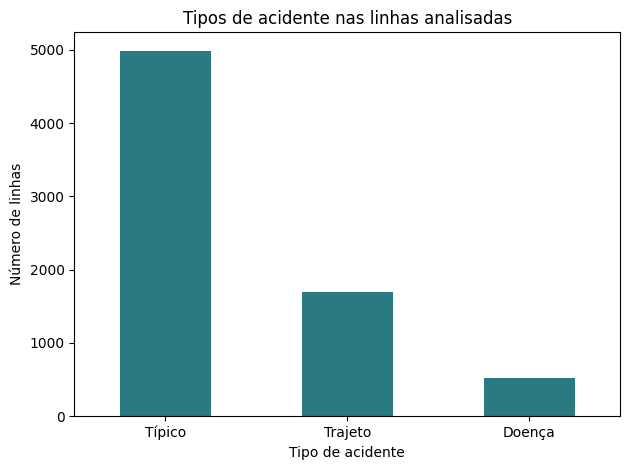

In [13]:
import matplotlib.pyplot as plt

tipos = base_conferencia["Tipo do Acidente"].str.strip()
contagem_tipos = tipos.value_counts()

tabela_tipos = pd.DataFrame({
    "Linhas": contagem_tipos,
    "Percentual (%)": (contagem_tipos / contagem_tipos.sum() * 100).round(2),
})

display(tabela_tipos)

grafico = contagem_tipos.plot.bar(color="#297A82", rot=0)
grafico.set_title("Tipos de acidente nas linhas analisadas")
grafico.set_xlabel("Tipo de acidente")
grafico.set_ylabel("Número de linhas")
plt.tight_layout()
plt.show()

Entre as 7.201 linhas distintas marcadas como Ceará e com data do acidente no semestre, cerca de 7 em cada 10 são do tipo típico. Doença é o tipo menos frequente, com 519 linhas. Quando compararmos os modelos, será importante ver quantos casos de cada tipo eles acertam.

## 7. Perfil por idade e sexo

In [14]:
data_acidente = pd.to_datetime(
    base_conferencia["Data Acidente"], format="%d/%m/%Y", errors="coerce"
)
data_nascimento = pd.to_datetime(
    base_conferencia["Data Nascimento"], format="%d/%m/%Y", errors="coerce"
)

mes_antes = data_acidente.dt.month < data_nascimento.dt.month
mes_igual = data_acidente.dt.month == data_nascimento.dt.month
dia_antes = data_acidente.dt.day < data_nascimento.dt.day
aniversario_pendente = mes_antes | (mes_igual & dia_antes)

idade = data_acidente.dt.year - data_nascimento.dt.year - aniversario_pendente.astype(int)

faixa_etaria = pd.cut(
    idade,
    bins=[0, 18, 30, 40, 50, 60, float("inf")],
    labels=["Até 17", "18 a 29", "30 a 39", "40 a 49", "50 a 59", "60 ou mais"],
    right=False,
)

sexo = base_conferencia["Sexo"].str.strip().replace({
    "Indeterminado": "Sem informação",
    "Não Informado": "Sem informação",
})

tabela_perfil = pd.crosstab(
    faixa_etaria, sexo, rownames=["Faixa etária"], colnames=["Sexo"]
)
tabela_perfil["Total"] = tabela_perfil.sum(axis=1)

display(tabela_perfil)

Sexo,Feminino,Masculino,Sem informação,Total
Faixa etária,,,,
Até 17,5,4,0,9
18 a 29,795,1290,7,2092
30 a 39,917,1062,0,1979
40 a 49,1022,895,2,1919
50 a 59,491,471,0,962
60 ou mais,106,134,0,240


Entre as linhas distintas marcadas como Ceará, a faixa de 18 a 29 anos foi a mais frequente, com 2.092 registros. A idade foi calculada na data do acidente, considerando se a pessoa já tinha feito aniversário naquele ano.

## 8. Atividades econômicas mais frequentes


,Código CNAE,Atividade,Linhas
0,8660,Apoio à gestão de saúde,780
1,8610,Atendimento hospitalar,725
2,5611,Restaurantes e similares,286
3,4120,Construção de edifícios,208
4,4711,Hipermercados e supermercados,198


Linhas sem código CNAE 234


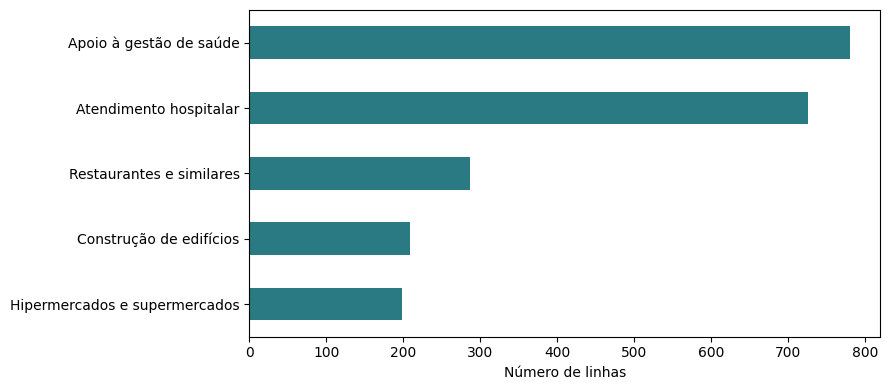

In [15]:
cnae = base_conferencia["CNAE2.0 Empregador"].str.strip()
sem_cnae = cnae.isin(["", "0000", "{ñ class}"])
mais_frequentes = cnae[~sem_cnae].value_counts().head(5)

nomes_atividades = {
    "8660": "Apoio à gestão de saúde",
    "8610": "Atendimento hospitalar",
    "5611": "Restaurantes e similares",
    "4120": "Construção de edifícios",
    "4711": "Hipermercados e supermercados",
}

tabela_cnae = mais_frequentes.rename_axis("Código CNAE").reset_index(name="Linhas")
tabela_cnae["Atividade"] = tabela_cnae["Código CNAE"].replace(nomes_atividades)

display(tabela_cnae[["Código CNAE", "Atividade", "Linhas"]])
print("Linhas sem código CNAE", sem_cnae.sum())

grafico = tabela_cnae.plot.barh(
    x="Atividade", y="Linhas", legend=False, color="#297A82", figsize=(9, 4)
)
grafico.invert_yaxis()
grafico.set_xlabel("Número de linhas")
grafico.set_ylabel("")
plt.tight_layout()
plt.show()

Entre as linhas distintas marcadas como Ceará, as atividades mais frequentes foram apoio à gestão de saúde (780 registros) e atendimento hospitalar (725). Essas contagens descrevem os registros da base. Para comparar o risco entre atividades, também precisaríamos saber quantas pessoas trabalham em cada uma.

## 9. Registros por mês do acidente

,Linhas
Mês do acidente,
Janeiro,1115
Fevereiro,1102
Março,1264
Abril,1202
Maio,1305
Junho,1213


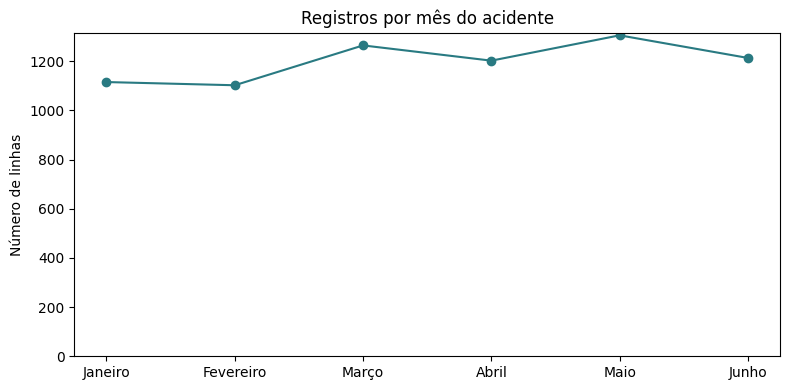

In [16]:
data_acidente = pd.to_datetime(
    base_conferencia["Data Acidente"], format="%d/%m/%Y", errors="coerce"
)

linhas_por_mes = data_acidente.dt.month.value_counts().reindex(range(1, 7), fill_value=0)
linhas_por_mes.index = ["Janeiro", "Fevereiro", "Março", "Abril", "Maio", "Junho"]

tabela_mensal = linhas_por_mes.rename_axis("Mês do acidente").to_frame("Linhas")
display(tabela_mensal)

grafico = linhas_por_mes.plot(marker="o", color="#297A82", figsize=(8, 4))
grafico.set_xticks(range(len(linhas_por_mes)), linhas_por_mes.index)
grafico.set_title("Registros por mês do acidente")
grafico.set_ylabel("Número de linhas")
grafico.set_ylim(bottom=0)
plt.tight_layout()
plt.show()

Entre as 7.201 linhas distintas marcadas como Ceará, maio teve a maior contagem, com 1.305 registros, e fevereiro teve a menor, com 1.102. A contagem mensal foi feita pela data do acidente.

## 10. Tempo entre o acidente e a emissão da CAT

In [17]:
data_emissao = pd.to_datetime(
    base_conferencia["Data Emissão CAT"], format="%d/%m/%Y", errors="coerce"
)

dias_ate_emissao = (data_emissao - data_acidente).dt.days

faixas_emissao = pd.cut(
    dias_ate_emissao,
    bins=[float("-inf"), -1, 0, 7, 30, float("inf")],
    labels=["Antes do acidente", "No mesmo dia", "1 a 7 dias", "8 a 30 dias", "Mais de 30 dias"],
)

tabela_emissao = faixas_emissao.value_counts(sort=False).to_frame("Linhas")
display(tabela_emissao)

print("Sem intervalo válido", dias_ate_emissao.isna().sum())
print("Mediana em dias", dias_ate_emissao.median())
print("Maior intervalo em dias", dias_ate_emissao.max())

,Linhas
Antes do acidente,0
No mesmo dia,388
1 a 7 dias,4343
8 a 30 dias,1923
Mais de 30 dias,547


Sem intervalo válido 0
Mediana em dias 4.0
Maior intervalo em dias 191


A faixa mais frequente foi de 1 a 7 dias entre o acidente e a emissão da CAT, com 4.343 registros. Em 547 registros, a emissão ocorreu mais de 30 dias depois do acidente.